# 元空间：科学备忘录

### 复动力系统中的相干性、熵与有效维度

**版本 8.0——科学版。** 原始表述：A. Panin，v7.2 宣言（《中道与和谐之边缘》）。科学修订、数值实验与文本：LLM 协作。日期：2026 年 10 月 26 日。

---

**摘要。** 本备忘录将 v7.2 宣言改写为可检验的形式：明确给出对象定义，区分定义与命题，提出带零模型的假设，并报告数值实验结果。主要结果有三项。（1）可观测量 $K$、$S_R$、$C$ 可归结为已知量——Kuramoto 序参量、Shannon 熵与正交容量；在窄带情形下 $K$ 与 $C$ 函数相关，因此“(E,C) 平面”并非独立的状态空间。（2）v7.2 的 $(E,C)$ 动力系统不存在极限环：向量场散度严格为负（Dulac 判据），非平凡平衡点必为稳定结点，特征值均为实数且为负；特征多项式的判别式在所有容许参数下为正。（3）以校准的统计决策取代“噪声 vs 天才”的判据：基于样本内增益的朴素阈值给出 FDR $\approx 0.81$，而 Benjamini–Hochberg 方法在排序质量相同的情况下将 FDR 控制在 $\approx 0.10$。文中还讨论了极限环存在的必要条件、测量方案与适用边界。

**关键词：** 相干性、序参量、熵、有效维度、极限环、Dulac 判据、多重检验、错误发现率。


## 0. 文档定位与阅读规则

本备忘录**不是物理理论，也不是宣言**。它是一次数学重构：一组定义、若干带证明的命题、一组可检验假设，以及数值实验报告。凡不能归入这些范畴的内容均已删除；逐条审计见 `docs/audit.md`（俄文）。

全文遵循五条规则：

1. **每个对象在使用前必须定义。** 没有定义的操作不视为操作。
2. **每个陈述都必须有真值和检验方式。** “公理”不是保护陈述免受检验的工具。
3. **每个数字都必须有单位、不确定度与来源。** 没有推导或误差线的数字不能作为模型参数。
4. **没有参考文献的冠名不构成证明。** 名称不能代替证明。
5. **隐喻只能作为注释**，不能作为论据。

| v7.2 中的内容 | v8 中的处理 |
|---|---|
| 22 条公理，其中包含玄学内容 | 4 个定义、3 个命题、5 个假设；其余删除或降级 |
| 把“极限环”当作既定事实 | 无极限环定理 + 极限环存在的必要条件 |
| 把“和谐之边缘”$\chi$ 当作判决规则 | 控制 FDR 的校准统计检验 |
| 把“中道”当作吸引子 | 平衡泛函 + 控制问题 |
| “维度量子”$\lambda$、六个球层、$\alpha_{\text{life}}=\pi$ | 删除：没有推导、单位或机制 |


In [1]:
import sys
import pathlib

ROOT = pathlib.Path.cwd()
while not (ROOT / "metaspace").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

from metaspace import Flow
from metaspace import experiments as ex
from metaspace.plotting import setup_style
from metaspace import (
    coherence,
    born_entropy,
    quadrature_capacity,
    participation_dimension,
    balance_functional,
    shannon_entropy,
)
from metaspace.dynamics import semi_implicit_trajectory

setup_style("zh")
plt.rcParams["figure.max_open_warning"] = 0

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("项目根目录:", ROOT)


Python: 3.13.1
NumPy: 2.3.4
Matplotlib: 3.10.8
项目根目录: C:\Users\afina\OneDrive\Dokumenty\deepseek-harness\default-workspace


## 1. 形式化核心

### 1.1 状态与可观测量

**定义 1.1（状态）。** 状态是二元组 $X=(\psi,\alpha)$，其中 $\psi\in\mathbb{C}^N$ 为复向量，$\alpha=a+ib\in\mathbb{C}$ 为切片参数。实部 $a\ge 0$ 解释为**有效维度**（可测量的量）；虚部 $b$ 是**解析延拓参数**。$b$ 不是拓扑意义上的维度：它没有度量、没有测度，也没有可独立测量的维度定义。“元空间”一词指这类状态的集合，而不是新的物理空间。

**定义 1.2（相干性、熵、容量）。** 对 $\psi\ne 0$：

$$
K(X)=\frac{\left|\sum_{i=1}^{N}\psi_i\right|}{\sum_{i=1}^{N}|\psi_i|}\in[0,1],
\qquad
p_i=\frac{|\psi_i|^2}{\sum_{j=1}^{N}|\psi_j|^2},
\qquad
S_R(X)=-\sum_{i=1}^{N}p_i\ln p_i\ge 0,
$$

$$
\bar\varphi=\arg\sum_{i=1}^{N}\psi_i,
\qquad
C(X)=\frac{\sum_{i=1}^{N}\left|\operatorname{Im}\left(e^{-i\bar\varphi}\psi_i\right)\right|^2}{\sum_{i=1}^{N}|\psi_i|^2}\in[0,1].
$$

$K$ 是加权的 Kuramoto 序参量（等幅时即标准序参量）；$S_R$ 是 Born 分布的 Shannon 熵；$C$ 是相对于平均相位正交分量的归一化方差。

**与 v7.2 的差别。** 宣言使用 $C=\sum_i\|\operatorname{Im}\psi_i\|^2$。该量在整体相位旋转 $\psi\mapsto e^{i\theta}\psi$ 下不具有不变性：其值依赖于任意的相位原点。v8 把原点固定在平均相位 $\bar\varphi$ 上，因此 $C$ 在整体 $U(1)$ 变换下不变，并且只有与这一约定一起才有意义。

**定义 1.3（有效维度）。** 对非负谱 $\lambda_i$（状态算子的特征值、奇异值或模态权重），定义

$$
D_{\mathrm{eff}}=\frac{\left(\sum_i\lambda_i\right)^2}{\sum_i\lambda_i^2}\in[1,N].
$$

对 $N$ 个等权模态，$D_{\mathrm{eff}}=N$；对单一模态，$D_{\mathrm{eff}}=1$。这是“复维度”实部的可操作替代：$D_{\mathrm{eff}}$ 可由数据估计，并带有置信区间。

**$a$ 与 $b$ 的操作地位。** 在具体模型中，$a$ 必须与选定的维度估计量（例如 $D_{\mathrm{eff}}$）等同；没有这种等同，$a$ 只是自由参数，而不是可观测量。同样，依赖 $b$ 的陈述只有在给定具体解析延拓后才可检验；v8 除平衡泛函的形式定义外不使用此类陈述。这一限制很重要：“复维度”本身不是可测量。

**定义 1.4（平衡泛函）。** 对 $N\ge 2$、由问题给定的参考维度 $a_{\mathrm{ref}}\ge 0$ 以及 $S_{\max}=\ln N$：

$$
\mu(X)=\frac{1}{5}\left[(1-K)+\frac{S_R}{S_{\max}}+C+\frac{|b|}{1+|b|}+\frac{|a-a_{\mathrm{ref}}|}{1+|a-a_{\mathrm{ref}}|}\right],
$$

$$
\nu(X)=\frac{1}{5}\left[K+\left(1-\frac{S_R}{S_{\max}}\right)+e^{-C}+\frac{1}{1+b^2}+\frac{1}{1+|a-a_{\mathrm{ref}}|}\right].
$$

两个泛函都落在 $[0,1]$ 内；$\mu$ 度量非相干性与混合，$\nu$ 度量秩序与“绝对性”。平衡集 $\{\mu=\nu\}$ 是余维一的曲面。与 v7.2 不同，这里没有特权维度 $\pi$：$a_{\mathrm{ref}}$ 由具体问题给定，而不是由数字命理学选定。定义 1.4 的经验内容取决于 $a$ 与 $b$ 如何定义；第 4 节的实验使用不含 $a,b$ 的简化版本。


In [2]:
rng = np.random.default_rng(7)

amplitudes = rng.gamma(2.0, 0.6, 12)
psi = amplitudes * np.exp(1j * rng.normal(0.0, 0.35, 12))
K = coherence(psi)
S = born_entropy(psi)
C = quadrature_capacity(psi)
D = participation_dimension(np.abs(psi) ** 2)

print(f"K = {K:.4f}（0 — 完全退相干，1 — 同步）")
print(f"S = {S:.4f} 奈特（最大值 ln 12 = {np.log(12):.4f}）")
print(f"C = {C:.4f}（0 — 相位位于同一轴）")
print(f"2(1-K) = {2 * (1 - K):.4f}")
print(f"D_eff = {D:.3f}")

aligned = np.array([1.0, 2.0, 3.0])
anti = np.array([1.0, -1.0])
zero_c = np.array([1.0, -1.0, 1.0])
print(f"\nK(同相) = {coherence(aligned):.4f}")
print(f"K(反相) = {coherence(anti):.4f}")
print(f"C(同相) = {quadrature_capacity(aligned):.4e}")
print(f"对 (1,-1,1)：C = {quadrature_capacity(zero_c):.1e}，K = {coherence(zero_c):.4f}"
      f"（C=0 不蕴含 K=1）")


K = 0.9466（0 — 完全退相干，1 — 同步）
S = 2.1738 奈特（最大值 ln 12 = 2.4849）
C = 0.0948（0 — 相位位于同一轴）
2(1-K) = 0.1067
D_eff = 7.753

K(同相) = 1.0000
K(反相) = 0.0000
C(同相) = 0.0000e+00
对 (1,-1,1)：C = 0.0e+00，K = 0.3333（C=0 不蕴含 K=1）


### 1.2 命题

**命题 1（相干性的界）。** 对任意 $\psi\ne0$，有 $0\le K\le1$。等号 $K=1$ 成立当且仅当所有非零分量具有同一相位：$\psi_i=r_i e^{i\varphi}$，$r_i\ge0$。

*证明.* 由三角不等式 $|\sum_i\psi_i|\le\sum_i|\psi_i|$ 得 $K\le1$。等号要求所有 $\psi_i$ 作为 $\mathbb{C}$ 中向量共线；对复数而言即具有共同辐角。$\square$

**命题 2（容量的规范不变性）。** 对任意 $\theta\in\mathbb{R}$，$C(e^{i\theta}\psi)=C(\psi)$。此外，$C=0$ 当且仅当所有 $e^{-i\bar\varphi}\psi_i$ 为实数，即各分量的相位为 $\bar\varphi$ 或 $\bar\varphi+\pi$。特别地，$K=1\Rightarrow C=0$；反之不成立：对 $\psi=(1,-1,1)$，有 $C=0$，但 $K=1/3$。

*证明.* 在 $\psi\mapsto e^{i\theta}\psi$ 下，平均相位平移为 $\bar\varphi\mapsto\bar\varphi+\theta$，因此 $e^{-i\bar\varphi}\psi$ 不变。其次，$C=0$ 意味着每个 $e^{-i\bar\varphi}\psi_i$ 的虚部为零，即每个分量位于平均相位坐标系中的实轴上。若所有相位相同，则 $K=1$；但相位为 $\bar\varphi+\pi$ 的分量同样具有零虚部，却会降低 $K$。$\square$

**命题 3（窄带下 $K$ 与 $C$ 的冗余）。** 设振幅相等，相位为 $\theta_i=\varphi+\delta_i$，其中 $\delta_i\sim\mathcal{N}(0,\sigma^2)$ 相互独立。则当 $N\to\infty$、$\sigma\to0$ 时，

$$
K=1-\frac{\sigma^2}{2}+O(\sigma^4),
\qquad
C=\sigma^2\left(1-\frac{1}{N}\right)+O(\sigma^4),
\qquad\text{从而}\qquad
C=2(1-K)+O(\sigma^4).
$$

*证明.* 展开 $e^{i\delta}=1+i\delta-\delta^2/2+O(\delta^3)$ 得 $\mathbb{E}e^{i\delta}=1-\sigma^2/2+O(\sigma^4)$，故 $K=|\mathbb{E}e^{i\delta}|=1-\sigma^2/2+O(\sigma^4)$。又 $\operatorname{Im}(e^{-i\bar\varphi}e^{i\theta_i})\approx\delta_i-\bar\delta$，所以 $C=\mathbb{E}[(\delta_i-\bar\delta)^2]+O(\sigma^4)=\sigma^2(1-1/N)+O(\sigma^4)$。$\square$

**推论。** $K$ 与 $C$ 不是独立坐标：在窄带情形下，它们相互决定到 $O(\sigma^4)$。若 v7.2 模型中的变量 $E$ 本身是 $K$ 的函数（例如 $E=1-K$），则 $(E,C)$ 是一条一维曲线，而不是平面。这并不意味着 $(E,C)$ 模型没有意义；它意味着，除非另有论证，不能把该模型宣布为基本状态空间。熵 $S_R$ 依赖振幅分布，通常与 $K$ 独立，因此 $(K,S_R)$ 是合法的二维可观测量组合。


σ ≤ 0.2 时 |C / 2(1-K) − 1| 的最大值： 0.030
σ = 1.0 时 C / 2(1-K) 的比值： 0.551
C 的 U(1) 不变性误差： 0.00e+00
有效维度：
  single mode    1.000
  uniform 4      4.000
  exponential    3.696


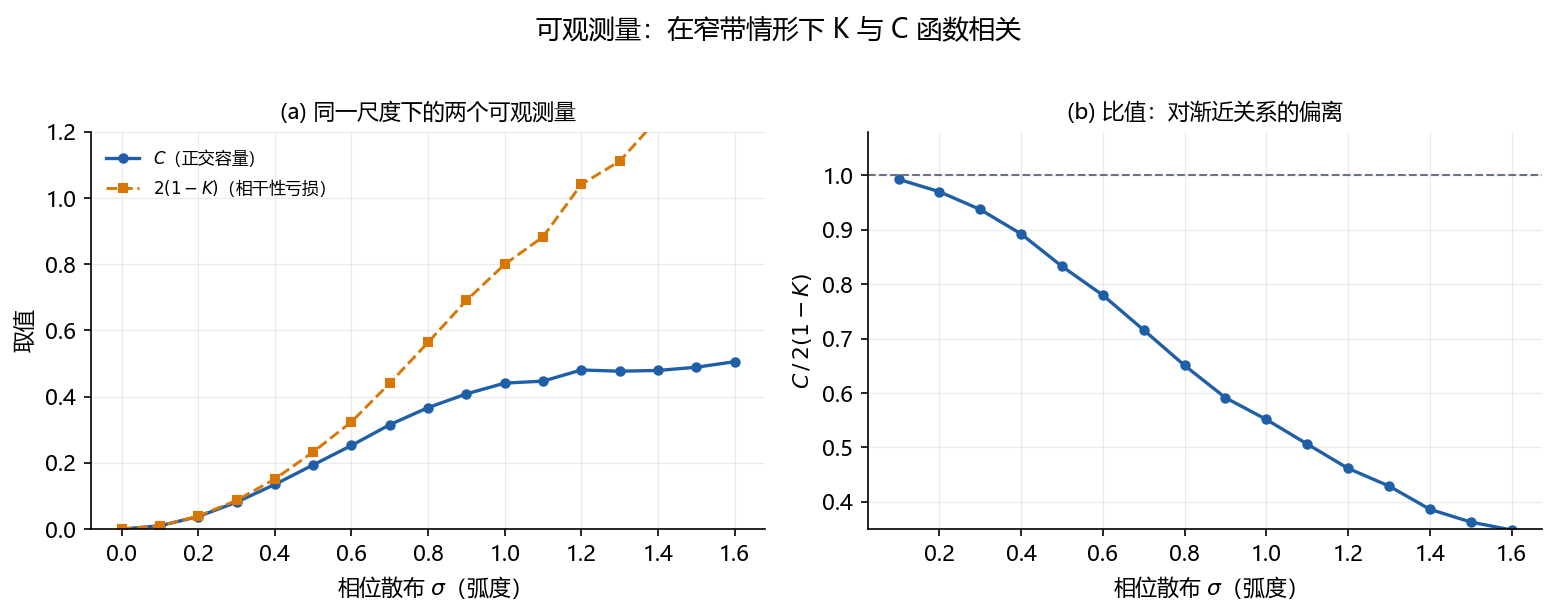

In [3]:
fig, m1 = ex.exp_observables(lang="zh")
print("σ ≤ 0.2 时 |C / 2(1-K) − 1| 的最大值：", f"{m1['ratio_small_sigma']:.3f}")
print("σ = 1.0 时 C / 2(1-K) 的比值：", f"{m1['ratio_at_sigma_1']:.3f}")
print("C 的 U(1) 不变性误差：", f"{m1['invariance_error']:.2e}")
print("有效维度：")
for name, value in m1["effective_dimensions"].items():
    print(f"  {name:14s} {value:.3f}")


**图 1.** 左：$C$ 与 $2(1-K)$ 随相位散布 $\sigma$ 的变化。两条曲线在 $\sigma\lesssim0.4$ 时重合，在更大的 $\sigma$ 处分离开来，此时命题 3 的展开失效。右：比值 $C/2(1-K)$；当 $\sigma\le0.2$ 时，偏离 1 不超过 3%（含有限 $N$ 误差）；当 $\sigma=1$ 时，比值降至约 0.55。

**这改变了什么。** v7.2 把 $K$ 与 $C$ 当作“相空间”的独立坐标。实验与命题 3 表明，在窄带情形下，它们只是同一信息的两种编码。只有在相位分布很宽或振幅不等时，独立性才出现——而那时必须测量它，而不是假定它。


### 1.3 熵：估计与偏差

$S_R$ 不是形而上的“选择熵”，而是分布 $p_i$ 的普通 Shannon 熵。用有限样本估计时，它存在向下偏倚：若 $m$ 个类别具有正概率，则

$$
\mathbb{E}[\hat S_R]-S_R\approx-\frac{m-1}{2N}.
$$

Miller–Madow 修正

$$
\hat S_R^{\mathrm{MM}}=\hat S_R+\frac{\hat m-1}{2N},
\qquad \hat m=\#\{i:\hat p_i>0\},
$$

在标准情形（$m$ 固定、所有类别被观测到的概率趋于 1）下把偏差降到 $O(N^{-2})$。

这对任何测量方案都很重要：没有修正时，不同样本量下的熵比较存在系统偏差，表观的“熵增”可能只是样本量的假象。


真实熵： 1.8381 奈特
N=200 时的偏差：代入估计 -0.0166 奈特；Miller–Madow 修正 +0.0008 奈特


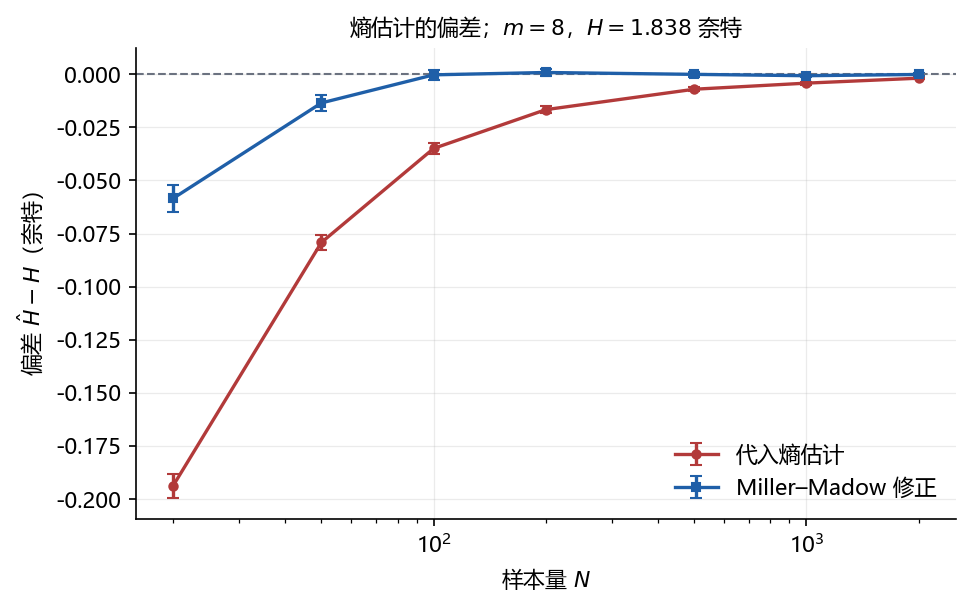

In [4]:
fig, m2 = ex.exp_entropy(lang="zh")
print("真实熵：", f"{m2['H_true']:.4f} 奈特")
print("N=200 时的偏差：代入估计", f"{m2['bias_at_200_plugin']:+.4f}", "奈特；Miller–Madow 修正",
      f"{m2['bias_at_200_mm']:+.4f}", "奈特")


**图 2.** 代入熵估计（红色圆点）与 Miller–Madow 估计（蓝色方块）的偏差随样本量的变化，误差线为 95% 区间。在 $N=200$ 时，代入估计约低 0.017 奈特；修正后偏差约为 0.001 奈特。

**对 v7.2 的推论。** “$S_R\to\max$”不能直接用原始样本熵检验：最大值在有限 $N$ 下不可达，跨样本比较也有偏。任何关于熵的陈述都必须针对偏差修正后的估计量，并给出置信区间。


## 2. $(E,C)$ 动力学：模型究竟断言了什么

### 2.1 模型

考虑 v7.2（第 5 节）的简化系统：

$$
\frac{dE}{da}=-AE+BC,
\qquad
\frac{dC}{da}=-\beta C+\gamma(C)E,
\qquad
\gamma(C)=\frac{\gamma_0}{1+(C/C_0)^2},
\tag{2.1}
$$

其中 $A,B,\beta,\gamma_0,C_0>0$，$E,C\ge0$ 为归一化的“误差”与“容量”。参数 $a$ 是维度的实部，即沿轨迹的参数；时间不进入系统。

**记号。** 第 1 节中 $C(X)$ 是正交容量泛函；式 (2.1) 中 $C$ 是表示容量的标量动力学变量。这是一种约化，而不是等同：下文把 $C$ 当作独立的模型变量，而不是状态泛函。

v7.2 断言 (2.1) 存在极限环。下文将证明，事实并非如此——而且在任何容许参数下都不可能。


### 2.2 定理 1：不存在周期轨道

**定理 1（Dulac）。** 设 $A,B,\beta,\gamma_0,C_0>0$，且对 $C\ge0$ 有 $\gamma'(C)\le0$。则系统 (2.1) 在闭第一象限 $E\ge0$、$C\ge0$ 内没有闭轨道。

*证明.* 取 Dulac 函数 $g(E,C)\equiv1$。向量场的散度为

$$
\nabla\cdot(gF)=\frac{\partial}{\partial E}(-AE+BC)+\frac{\partial}{\partial C}\left(-\beta C+\gamma(C)E\right)
=-A-\beta+E\gamma'(C)\le-(A+\beta)<0.
$$

若存在一条闭轨道围成区域 $\Omega$，则由散度定理

$$
0=\oint_{\partial\Omega}F\cdot n\,ds=\int_\Omega\nabla\cdot F\,dA<0,
$$

矛盾。$\square$

**有界性与 $\omega$-极限集。** 在典型参数范围内，轨迹保持在紧区域中：当 $E$ 很大时 $\dot E$ 为负，而两个导数同时为正的区域由 $\gamma(C)\sim C^{-2}$ 的衰减限制。对典型参数的数值检验证实了这一点。对任意容许参数，有界性是需要单独检查的附加条件；没有它，Poincaré–Bendixson 定理不适用。若有界性成立，$\omega$-极限集由平衡点或闭轨道组成；由定理 1 不存在闭轨道，故极限集为平衡点。


### 2.3 定理 2：平衡点必为稳定结点

**定理 2.** 设 $u=\gamma_0B/(A\beta)-1>0$。则 (2.1) 存在唯一内部平衡点

$$
C^*=C_0\sqrt{u},
\qquad
E^*=\frac{B}{A}C^*,
$$

且该平衡点为稳定结点：雅可比矩阵的特征值均为实数且为负。

*证明.* 令右端为零，得 $C=(A/B)E$ 与 $\beta C=\gamma(C)E$。把第一式代入第二式得 $\gamma(C^*)=A\beta/B$，于是 $u=(\gamma_0B/(A\beta))-1=(C^*/C_0)^2$，$C^*,E^*$ 的公式随之成立。

平衡点处的雅可比矩阵为

$$
J=\begin{pmatrix}-A & B\\ \gamma(C^*) & -\beta+E^*\gamma'(C^*)\end{pmatrix}.
$$

令 $x=-E^*\gamma'(C^*)>0$（因为 $\gamma'<0$）。则

$$
\operatorname{tr}J=-(A+\beta)-x<0,
\qquad
\det J= A x>0,
$$

$$
\Delta=(\operatorname{tr}J)^2-4\det J=(A-x)^2+2\beta(A+x)+\beta^2>0.
$$

该式对一切 $A,\beta,x>0$ 为正。因此两个特征值均为实数；其和为负、积为正，故二者均为负。$\square$

**显式公式。** 由 $u=(C^*/C_0)^2$ 与 $\gamma(C^*)=A\beta/B$，

$$
x=-E^*\gamma'(C^*)=\frac{2\beta u}{1+u}\in(0,2\beta).
$$

因此 $\operatorname{tr}J<-(A+\beta)$，且对一切 $A,\beta,x>0$ 有 $\Delta=(A-x)^2+2\beta(A+x)+\beta^2>0$；结论不依赖于 $u$ 的具体取值。

**推论 1.** 不存在极限环；进一步，也不存在衰减振荡，因为特征值为实数。系统无振荡地松弛到结点。

**推论 2.** 在线性近似下，随机“准周期”解释同样不可能：对于特征值为实数的稳定结点，功率谱密度没有内部极大值。在此类模型中观察到的任何振荡都需要外部周期驱动或方程的结构性改变。

**投影。** 在 v7.2 中，$\chi$ 不进入 (2.1) 的右端。因此扩展空间 $(E,C,\chi)$ 中的任何确定性极限环都会投影为 (2.1) 的闭轨道；由定理 1，后者不存在。$\chi$ 的随机动力学可以产生随机涨落，但不是极限环。


平衡点： E* = 1.224745, C* = 1.224745
特征值： [-2.76619 -0.43381]
tr J = -3.2000  det J = 1.2000  Δ = 5.4400
数值收敛速率： 0.4443
[0,4]^2 上的最大散度： -2.0000
参数网格上的最小 Δ： 4.3265
rho(J_map)：最小值 = 0.3457  最大值 = 0.9957
半隐式格式在测试范围内稳定： True


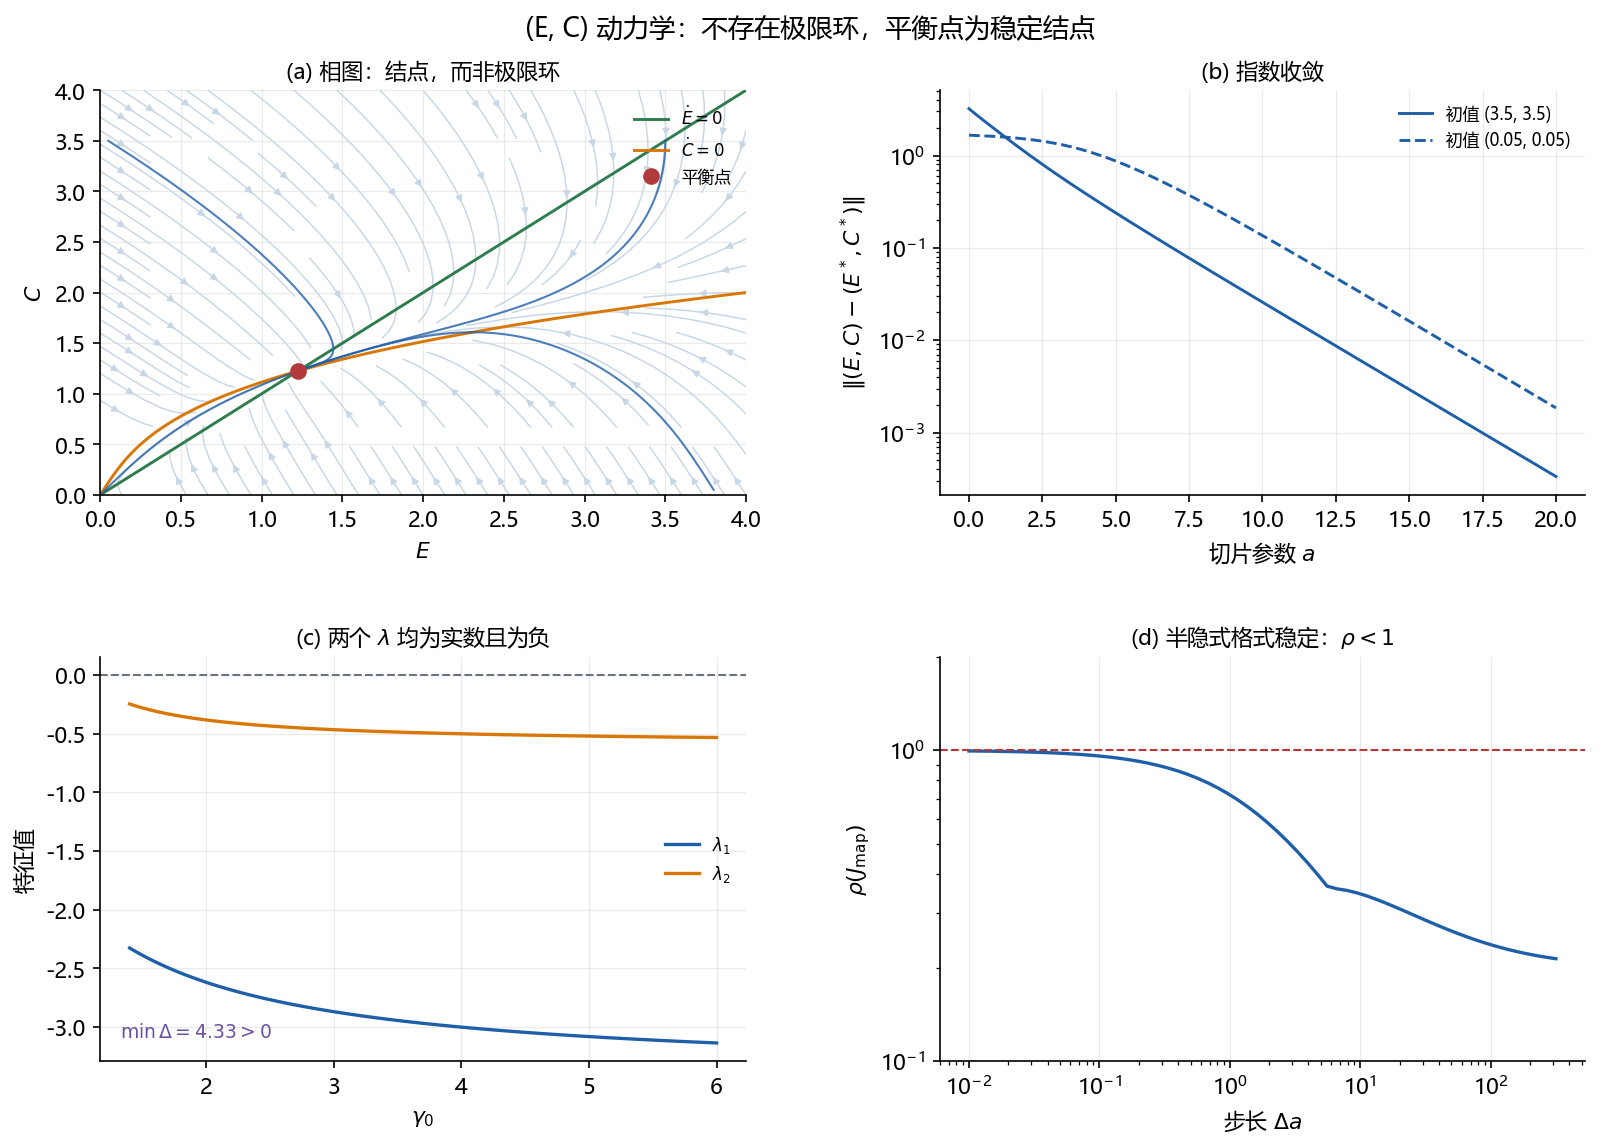

In [5]:
flow = Flow()
fig, m3 = ex.exp_dynamics(flow, lang="zh")
print("平衡点：", f"E* = {m3['fixed_point'][0]:.6f}, C* = {m3['fixed_point'][1]:.6f}")
print("特征值：", np.round(m3["eigenvalues"], 6))
print("tr J =", f"{m3['trace']:.4f}", " det J =", f"{m3['det']:.4f}", " Δ =", f"{m3['disc']:.4f}")
print("数值收敛速率：", f"{m3['convergence_rate']:.4f}")
print("[0,4]^2 上的最大散度：", f"{m3['max_divergence_on_grid']:.4f}")
print("参数网格上的最小 Δ：", f"{m3['min_discriminant_on_grid']:.4f}")
print("rho(J_map)：最小值 =", f"{m3['min_map_radius']:.4f}", " 最大值 =", f"{m3['max_map_radius']:.4f}")
print("半隐式格式在测试范围内稳定：", m3["map_stable_for_all_tested_deltas"])


**图 3.** (a) 相图：所有轨迹收敛到结点 $(1.2247,1.2247)$；彩色线为零等斜线。(b) 指数收敛：半对数图的斜率对应约 0.44 的速率，接近 $|\lambda_{\max}|=0.434$。(c) 特征值随 $\gamma_0$ 的变化：二者均为实数且为负，判别式处处为正（$\min\Delta=4.33$）。(d) 半隐式格式雅可比矩阵的谱半径：在整个测试范围 $10^{-2}\le\Delta a\le10^{2.5}$ 内 $\rho<1$。

**解释。** v7.2 关于极限环的断言不成立：连续系统没有极限环，其标准离散化也没有。更强的结果是：平衡点必为结点，因此模型连振荡型暂态都没有。这不是“关于特例的否定结果”，而是类 (2.1) 在 $\gamma'\le0$ 下的结构性性质。


### 2.4 离散化不会产生极限环

v7.2 使用半隐式格式

$$
E_{n+1}=\frac{E_n+\Delta a\,B C_n}{1+A\Delta a},
\qquad
C_{n+1}=\frac{C_n+\Delta a\,\gamma(C_n)E_{n+1}}{1+\beta_1\Delta a}.
\tag{2.2}
$$

其不动点与 (2.1) 的平衡点重合。映射在平衡点处雅可比矩阵的谱半径 $\rho(\Delta a)$ 决定局部稳定性。数值上，在整个范围 $10^{-2}\le\Delta a\le10^{2.5}$ 内 $\rho<1$；并且当 $\Delta a\to0$ 时 $\rho\to1$（符合一阶格式的预期），$\rho$ 随步长增大而减小。因此，v7.2 所宣称的“循环性”在典型参数下也不能用离散化假象解释。

**注意。** 在极端且物理上不允许的参数下，格式可能失稳：例如 $A=0.118$、$B=7.316$、$\beta=5.86$、$\gamma_0=6.311$、$C_0=0.2$、$\Delta a=1.288$ 时，迭代 (2.2) 进入周期 2，$E\approx270$–$300$，对应大于 1 的“误差”，已超出归一化范围。这并不能为极限环翻案；它说明复现时必须报告 $\rho$ 与参数范围。


In [6]:
extreme = Flow(A=0.118, B=7.316, beta=5.86, gamma0=6.311, C0=0.2)
trajectory = semi_implicit_trajectory(extreme, 1.288, n_steps=20000)
last = trajectory[-1000:]
print("rho(J_map) =", f"{extreme.map_spectral_radius(1.288):.3f}", "（> 1：局部不稳定）")
print("最后 1000 次迭代的 E：最小值 =", f"{last[:, 0].min():.2f}",
      "，最大值 =", f"{last[:, 0].max():.2f}")
print("最后 4 个 E 值：", np.round(trajectory[-4:, 0], 2))
print("最后 4 个 C 值：", np.round(trajectory[-4:, 1], 2))


rho(J_map) = 1.548 （> 1：局部不稳定）
最后 1000 次迭代的 E：最小值 = 269.53 ，最大值 = 299.95
最后 4 个 E 值： [299.95 269.53 299.95 269.53]
最后 4 个 C 值： [1.12 8.07 1.12 8.07]


### 2.5 极限环存在的必要条件

对二维自治系统，产生极限环的标准途径是 Hopf 分岔；它要求在某个点满足

$$
\operatorname{tr}J=0,
\qquad
\det J>0.
$$

在类 (2.1) 中，当 $\gamma'\le0$ 时，平衡点处 $\operatorname{tr}J<-(A+\beta)<0$，因此 Hopf 分岔不可能发生。需要结构性改变。最小方案有：

1. **拮抗耦合。** 使其中一项为负（容量抑制误差、误差刺激容量）。此时可能出现复特征值与稳定焦点；要产生极限环，还需要失稳，即正反馈或时滞。
2. **时滞。** 模型

$$
\dot E=-AE-BC(a-\tau)+S,
\qquad
\dot C=-\beta C+\gamma E
\tag{2.3}
$$

的特征方程为

$$
(\lambda+A)(\lambda+\beta)+B\gamma e^{-\lambda\tau}=0.
$$

代入 $\lambda=i\omega$，得到 Hopf 条件 $B\gamma>A\beta$ 与频率

$$
\omega^2=\frac{-(A^2+\beta^2)+\sqrt{(A^2+\beta^2)^2-4(A^2\beta^2-B^2\gamma^2)}}{2},
$$

临界时滞 $\tau_c$ 由相位条件给出：

$$
\cos(\omega\tau)=\frac{\omega^2-A\beta}{B\gamma},
\qquad
\sin(\omega\tau)=\frac{\omega(A+\beta)}{B\gamma}>0.
$$

线性模型 (2.3) 在 $B\gamma>A\beta$ 且 $\tau>\tau_c$ 时产生增长振荡；稳定的极限环需要限制振幅的非线性。这是关于机制的独立假设，而不是 v7.2 的推论。

3. **自催化。** 正的对角贡献（例如 $E$ 方程中的 $\delta EC$，或 $C$ 方程中的 $\delta C^2$）可以使 $\operatorname{tr}J$ 为正。但此时必须单独检查：平衡点是否存在、稳定性是否真的丧失、非线性是否限制振幅；仅有一个正对角项并不能保证任何事。

**结论。** v7.2 的极限环不是模型的结果，而是一种预设的可能性。要把它变成科学陈述，必须指明机制（时滞、拮抗、自催化），测量其参数，并证明系统确实处于相应区域。否则，“极限环”只是缺乏依据的解释。


## 3. 从 $\chi$ 启发式到校准检测

### 3.1 检测问题

设有 $n$ 个观测与 $p$ 个候选特征。对每个特征 $j$ 计算样本内增益 $R^2_{\mathrm{in},j}$（例如加入该特征后解释方差的增量）。任务是判断哪些特征有实质内容、哪些是噪声。

v7.2 使用指标

$$
\chi(X)=\frac{\mu(X)}{\nu(X)}\cdot\frac{1-\langle\cos\Delta\phi\rangle_{\text{env}}}{1+|\Delta\alpha|/\lambda},
$$

以及“动态”阈值 $\chi_{\text{crit}}$。该规则没有零分布：$\chi$ 没有概率模型，阈值也不控制任何频率错误。因此，“天才离群点”与“寄生虚性”不是统计上可区分的类别——它们只是同一事件的标签：较大的样本内增益。

### 3.2 可测量的量

对选出的集合 $S$：

$$
\text{precision}=\frac{TP}{|S|},
\qquad
\text{recall}=\frac{TP}{k},
\qquad
\text{FDR}=\mathbb{E}\left[\frac{FP}{|S|}\right],
$$

其中 $k$ 为真实特征数（模拟中已知，实际问题中未知）。此外，样本外增益 $R^2_{\mathrm{out}}$ 衡量效应能否迁移到新数据。

比较三种程序：

* **朴素阈值（top-$m$）：** 选取 $R^2_{\mathrm{in}}$ 最大的 $m$ 个特征。错误率不受控制。
* **Benjamini–Hochberg（BH）：** 用 $p$ 值与水平 $q$ 的 step-up 程序；在独立或正相关（PRDS）下控制 FDR。
* **置换最大值：** 在随机置换标签下模拟 $\max_j R^2_{\mathrm{in}}$ 的分布，取其 $1-\alpha$ 分位数；控制族错误率（FWER）。

### 3.3 实验

参数：$n=100$，$p=200$，$k=2$ 个真实特征，效应 $0.45$，1000 次重复，朴素预算 $m=10$，$q=0.1$，500 次置换。


朴素 top-10 精确率=0.195 召回率=0.975 FDR=0.805 R2_out=-0.022 AUC=0.994
BH，q=0.1 精确率=0.896 召回率=0.754 FDR=0.097 R2_out=+0.111 AUC=0.994

top-10 阈值： 0.035
零分布 95% 分位数： 0.129
赢家诅咒：平均 R2_in = 0.188 ，平均 R2_out = 0.129


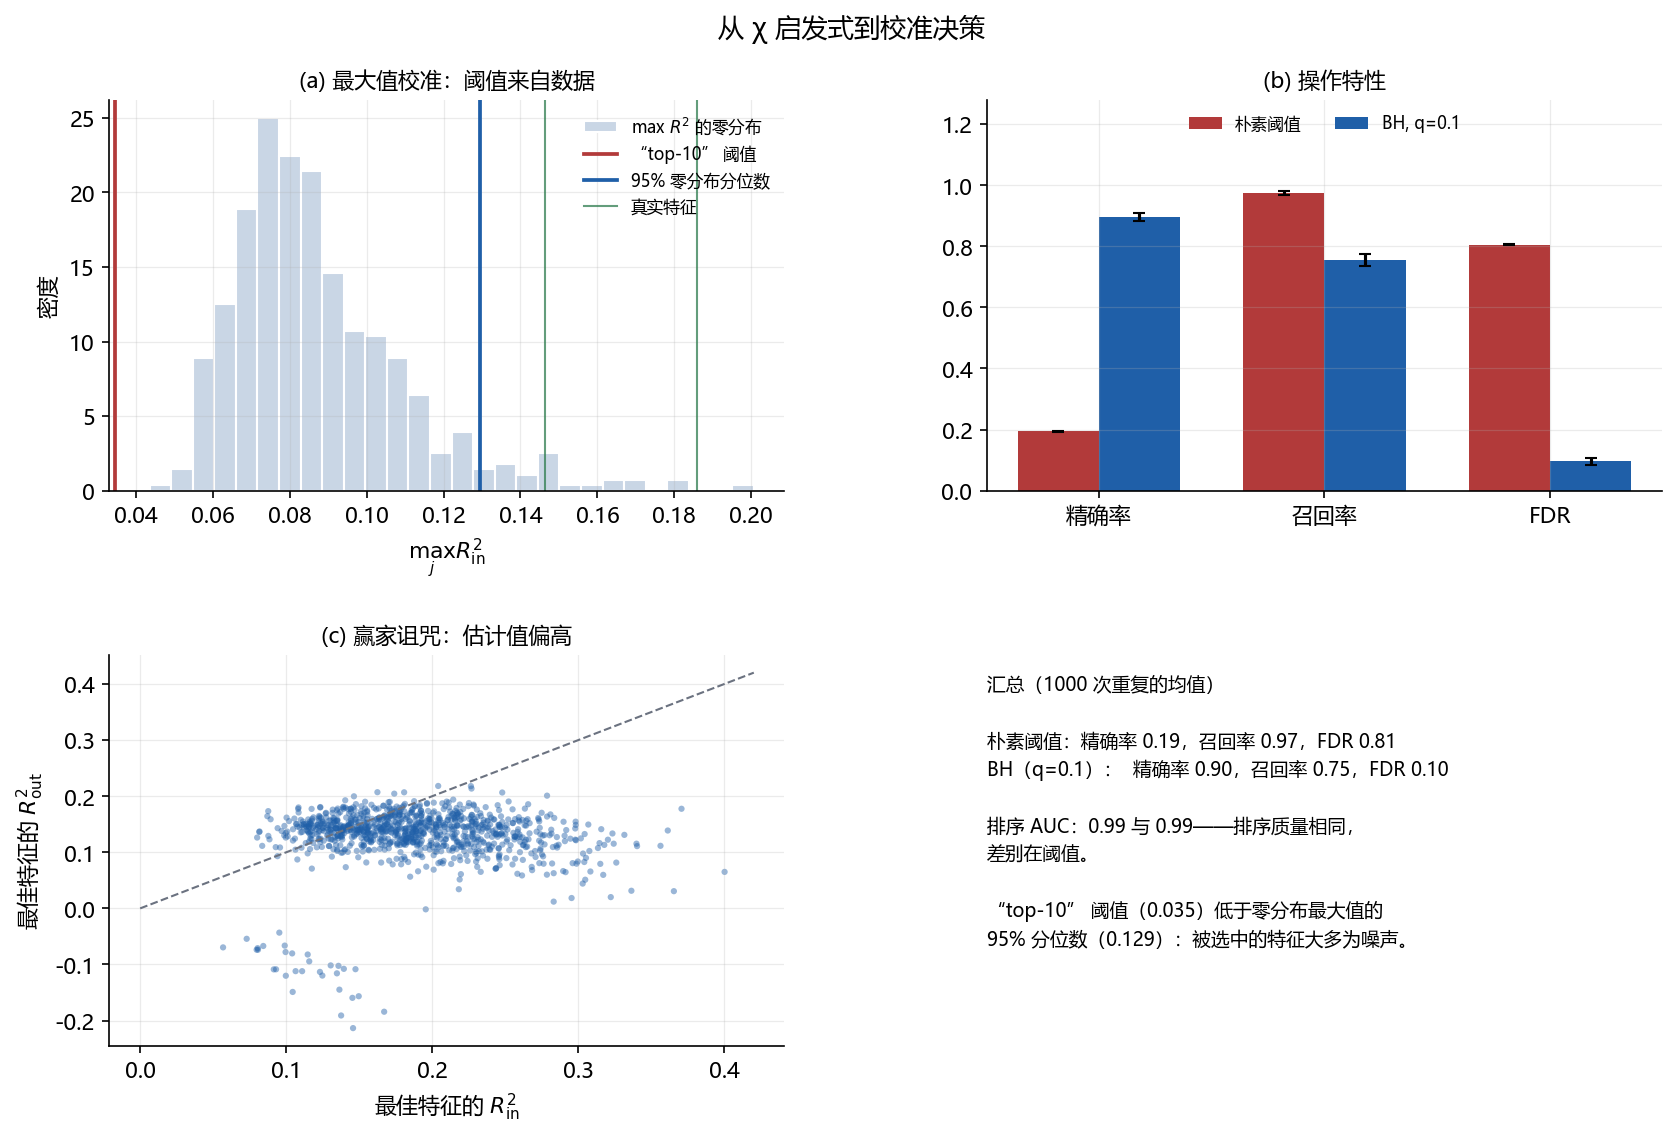

In [7]:
fig, m5 = ex.exp_detection(reps=1000, n_perm=500, lang="zh")
for key, label in (("raw_top", "朴素 top-10"), ("bh", "BH，q=0.1")):
    mm = m5["metrics"][key]
    print(label, f"精确率={mm['precision']:.3f}", f"召回率={mm['recall']:.3f}",
          f"FDR={mm['fdr']:.3f}", f"R2_out={mm['mean_out_of_sample_r2']:+.3f}",
          f"AUC={mm['auc']:.3f}")
print("\ntop-10 阈值：", f"{m5['example']['raw_cut']:.3f}")
print("零分布 95% 分位数：", f"{m5['example']['null_q95']:.3f}")
print("赢家诅咒：平均 R2_in =", f"{m5['winner']['in_sample'].mean():.3f}",
      "，平均 R2_out =", f"{m5['winner']['out_of_sample'].mean():.3f}")


**图 4.** (a) 置换标签下 $\max R^2_{\mathrm{in}}$ 的零分布（500 次置换）、其 95% 分位数（蓝线）、朴素 top-10 阈值（红线）以及真实特征的得分（绿线）。朴素阈值低于零分布分位数：它选出的特征大多是噪声。(b) 朴素阈值与 BH 的精确率、召回率与 FDR，误差线为 95% 区间。(c) 最佳特征的样本内增益对样本外增益：点大多位于对角线下方，说明估计向上偏置。

**结果。** 朴素阈值：精确率 $0.20$，召回率 $0.97$，FDR $0.81$，$R^2_{\mathrm{out}}=-0.02$。BH：精确率 $0.90$，召回率 $0.75$，FDR $0.10$，$R^2_{\mathrm{out}}=+0.11$。两种方法的排序 AUC 均约为 $0.99$：**按样本内增益排序本身是好的；问题在阈值。** 这就是为什么把“魔法”$\chi_{\text{crit}}$ 换成校准阈值可以在不改变排序的情况下带来收益。

**对公理 22 的推论。** “天才”不是可由 $\chi$ 识别的独立本体论范畴。它是一个小效应，满足：(i) 通过校准；(ii) 在新数据上可复现；(iii) 报告了效应量与置信区间。朴素阈值系统性地混淆噪声与信号；校准程序控制错误发现率，但不保证每一个发现都为真。“对任意有限 $n$ 都保留天才”的普遍保证并不存在：这是统计学无免费午餐原理的直接推论。

**说明。** 本实验并未逐字计算 $\chi$：它模拟 $\chi$ 门控的关键性质——在没有零分布的情况下按样本内增益选择。对 $\chi$ 的直接检验需要已知真值的数据，留待现场阶段（H3）。


## 4. 中道作为控制问题

### 4.1 平衡泛函

在简化 $(E,C)$ 模型中定义

$$
\mu(E,C)=\frac12\left[\frac{E}{1+E}+\frac{C}{1+C}\right],
\qquad
\nu(E,C)=\frac12\left[\frac{1}{1+E}+\frac{1}{1+C}\right].
$$

则 $\mu+\nu=1$，且

$$
\mu-\nu=\frac{EC-1}{(1+E)(1+C)}.
$$

平衡集 $\{\mu=\nu\}$ 是双曲线 $EC=1$。这是定义 1.4 同一思想的二维版本：余维一，而不是一个点，也不是吸引子。

### 4.2 自由动力学

对 (2.1)，平衡点满足 $E^*C^*=(1.2247)^2=1.5$，因此位于平衡集之外：$\mu-\nu\approx0.10$。从 $(0.05,0.05)$ 出发的轨迹恰好穿过 $EC=1$ 一次，然后趋向平衡点。平衡是**暂态事件**，而不是系统追求的状态。

### 4.3 控制

在 $E$ 的方程中加入控制输入 $u$，得

$$
\frac{d(EC)}{da}=C(-AE+BC+u)+E(-\beta C+\gamma(C)E).
$$

取

$$
u=\frac{-k(EC-1)+(A+\beta)EC-BC^2-\gamma(C)E^2}{C}
$$

（当 $C>0$）可得 $\frac{d(EC)}{da}=-k(EC-1)$，即 $EC\to1$ 指数收敛。这不是“自然定律”，而是一个演示：若系统具有相应反馈，平衡是可以达到的。具体系统是否具有这种反馈，是经验问题。


平衡点：E*C* = 1.5000 ，平衡缺口 = 0.1010
无控制时 EC=1 的穿越次数： 1
受控时 EC=1 的穿越次数： 0
受控最终 EC： 1.000000
受控最终 |EC−1|： 5.33e-15


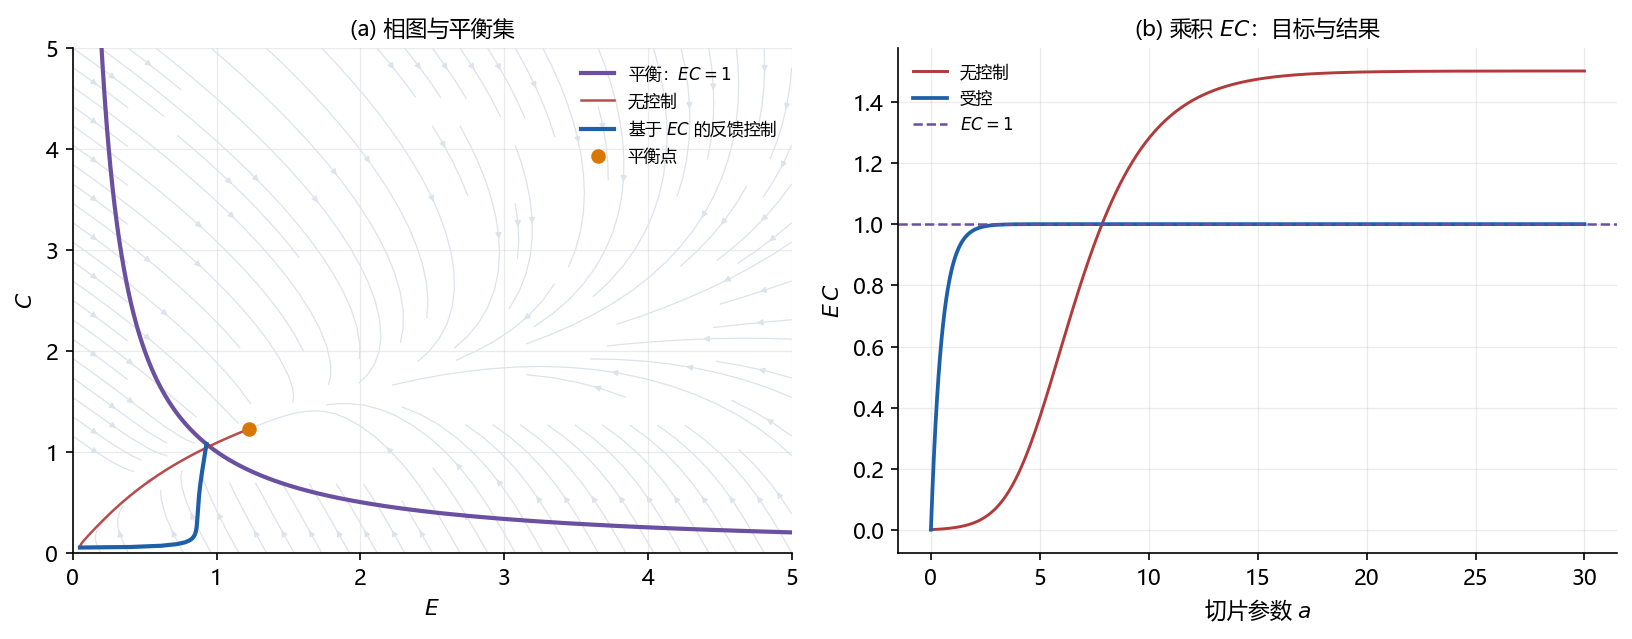

In [8]:
flow = Flow()
fig, m4 = ex.exp_balance(flow, lang="zh")
print("平衡点：E*C* =", f"{m4['equilibrium_product']:.4f}",
      "，平衡缺口 =", f"{m4['equilibrium_gap']:.4f}")
print("无控制时 EC=1 的穿越次数：", m4["uncontrolled_crossings"])
print("受控时 EC=1 的穿越次数：", m4["controlled_crossings"])
print("受控最终 EC：", f"{m4['controlled_final_product']:.6f}")
print("受控最终 |EC−1|：", f"{m4['controlled_final_abs_gap']:.2e}")


**图 5.** (a) 相图、平衡双曲线 $EC=1$、自由轨迹（红色）与带反馈的轨迹（蓝色）；自由系统的平衡点位于双曲线之外。(b) 沿轨迹的乘积 $EC$：自由系统经过 1 后趋向 1.5；受控系统到达 1 并保持。

**对公理 21 的推论。** “中道是吸引子”的断言在简化模型中不成立：平衡被横截穿过，且不能保持。正确的表述是：**平衡是一个可由控制稳定的目标集。** 可检验的假设是：某个具体系统具有使 $\mu\approx\nu$ 的反馈；这应表述为关于在 $\{\mu=\nu\}$ 邻域内停留时间与对扰动响应的问题，而不是公理。


## 5. 假设与可证伪性

下表列出可检验、原则上可反驳的最小陈述集。每个假设给出预测、零模型与当前状态。

| 编号 | 假设 | 预测 | 零模型 / 检验 | 状态 |
|---|---|---|---|---|
| **H1** | 类 (2.1) 在 $A,B,\beta>0$、$\gamma'\le0$ 下没有持续振荡 | 功率谱密度无内部极大值（线性近似）；无准周期峰 | 谱检验：实根 AR(2) 与复根 AR(2) 的对比；定理 1–2 | 已由解析与数值支持 |
| **H2** | 窄带下 $K$ 与 $C$ 冗余 | $\sigma\to0$ 时 $C/2(1-K)\to1$；$\sigma<0.3$ 时偏离 $<5\%$ | 对 $\sigma$ 的 Monte Carlo；命题 3 | 已支持 |
| **H3** | 朴素 $\chi$ 阈值不控制 FDR | $\mathrm{FDR}_{\text{naive}}>0.5$，而 $\mathrm{FDR}_{\text{BH}}\le0.15$ | 回归代理实验（第 3 节） | 代理上支持；需现场数据检验 |
| **H4** | 平衡集不是自由系统的吸引子 | 穿越次数有限；$\mu-\nu$ 不收敛到 0 | 直接积分 (2.1)；计数穿越 | 在简化模型中支持 |
| **H5** | 相干正则化提高复值分类器对相位噪声的鲁棒性 | 在相同参数数量下，相位噪声中的精度高于基线 | 预注册实验：相位编码任务、实值基线、20 个随机种子 | 计划中 |

**这些假设不主张什么。** 它们不主张“元空间”作为物理实在存在，不主张维度可以在度量空间意义上为复数，也不主张相干性是自然的普遍货币。它们只主张：所列量是可测量的，所列关系是可检验的。

**停止规则。** 实验不在“$\langle\chi\rangle$ 在极限环上稳定”时停止，而在达到预先设定的效应估计精度并控制 FDR 时停止。该规则可复现，且不依赖解释。


## 6. 删除了什么，以及为什么

对 22 条公理、7 条“定理”以及代数、拓扑、微积分与应用各节的完整审计见 `docs/audit.md`（俄文）。以下按类别汇总。

| v7.2 中的内容 | v8 中的处理 | 理由 |
|---|---|---|
| “维度量子”$\lambda=0.020203236\ldots$、六个球层（7,6,5,4,3,2 种形态） | 删除 | 没有推导、单位、不确定度或独立测量；数字不由模型推出 |
| $\alpha_{\text{life}}=\pi$ | 删除 | $\pi$ 不是维度；没有机制解释生命为何需要该值 |
| 除以零 $X\oslash\mathbf{0}_{\mathfrak{M}}$ | 删除 | 运算未定义；“提升维度”不来自数学。真正的类比是重整化与反常维度 $d_{\mathrm{eff}}=d+\gamma$，后者是可计算的 |
| “虚零”$\mathbf{0}_{\text{imag}}$、$\mathbf{1}_{\text{imag}}^2=-\mathbf{1}$ | 删除 | $\mathbb{C}$ 是标准的，$i^2=-1$ 不需要新公理；“虚零”未定义，不给定运算就无法检验其相容性。幂零对象可用 Grassmann 代数（$\theta^2=0$，$\theta_i\theta_j=-\theta_j\theta_i$），但它并不来自“虚性” |
| 带超对称伙伴的超对称 | 作为物理主张删除 | 没有预言或粒子；只保留 $\mathbb{Z}_2$ 分级作为数学类比 |
| 自虚性（对任意 $X$ 存在 $\varphi_X$） | 删除 | 同义反复：$\varphi_X=\mathrm{id}$ 即满足；陈述不包含信息 |
| “Poincaré–Perelman 定理”“$\mathfrak{M}$ 的 Fermat 定理” | 删除 | 未表述为数学陈述：没有空间、运算、量词与证明 |
| 代数 $\oplus,\otimes,\circledast,\oslash$；群 $\mathcal{G}_{\mathfrak{M}}$ | 删除 / 不使用 | 运算未在公共载体上定义；逆元公式未按逆元检验。v8 只需 $\mathbb{C}^N$ 上的标准运算 |
| 拓扑：连通分支 $\mathcal{C}_0,\mathcal{C}_{\mathrm{IV}},\mathcal{C}_{\mathrm{III}},\mathcal{C}_{\mathrm{II}}$；$\pi_1=\mathbb{Z}\oplus\mathbb{Z}_2$ | 删除 | 没有定义、映射与证明；基本群断言不可检验 |
| 复阶分数导数；“微分提升维度” | 删除 | Grünwald–Letnikov 公式定义在实阶；复阶需要单独定义。微分不提升维度 |
| 应用：聚变、弦论、“暗物质” | 删除 | 没有计算、单位或可检验预言；按当前形式不构成科学假设 |
| 反第二定律 | 降级 | 作为普遍陈述为假（退相干增加 $S_R$ 并降低 $K$）；代之以开放系统的熵平衡 |
| Poincaré 回归 | 重述 | 适用于有限测度的保守系统；(2.1) 是耗散系统，不能保证回归 |
| 哲学引文 | 从科学文本中删除 | 不是可检验陈述；可保留在通俗表述中 |

**保留了什么。** $K$、$S_R$、$C$ 的定义；复参数 $\alpha=a+ib$ 作为有效维度加解析延拓参数的思想；函数空间层级作为数学构造；平衡泛函；以及 $\chi$ 作为起点启发式（而不是判决规则）。

**审计计数。** 22 条公理中，5 条作为定义或构造保留，4 条重述或限制，4 条降级为假设或任务，9 条删除。7 条“定理”中没有一条以原形式保留定理地位；两条由正确陈述（上文定理 1–2）替代，其余删除。


## 7. 可复现性与研究纲领

**环境。** Python $\ge3.11$，`numpy`、`scipy`、`matplotlib`。完整列表见 `requirements.txt`；安装包用 `pip install -e .`。

**命令。**

```bash
python experiments/run_all.py          # 生成全部图与 results/metrics.json
python tests/test_core.py              # 16 个测试，无需 pytest
python tools/build_notebook.py         # 重建俄文版
python tools/build_notebook_en.py      # 重建英文版
python tools/build_notebook_zh.py      # 重建本中文版
```

**数据与随机种子。** 所有实验确定：E1 为 `seed=0`，E2 为 `seed=0`，E3/E4 无随机性，E5 为 `seed=1`。正文数字对应 `results/metrics.json`；改变参数后会重新计算。

**运行时间。** 完整运行数秒；检测实验（1000 次重复、500 次置换）约 4 秒。

**结构。**

```
metaspace/                 # 库：可观测量、动力学、平衡、统计
experiments/run_all.py
tests/test_core.py
tools/build_notebook.py    # 俄文版
tools/build_notebook_en.py # 英文版
tools/build_notebook_zh.py # 中文版
notebooks/metaspace_v8.ipynb
notebooks/metaspace_v8_en.ipynb
notebooks/metaspace_v8_zh.ipynb
results/figures/
results/metrics.json
docs/audit.md
```

**研究纲领。**

* *理论（0–6 个月）。* 按雅可比矩阵的符号结构分类 (2.1) 的二维与三维扩展；研究超出 $\gamma'\le0$ 的全局稳定性；推导时滞与拮抗的 Hopf 条件；区分机制与曲线拟合。把结构性否定结果（定理 1–2）作为独立论文发表。
* *测量（6–12 个月）。* 实现 $K$、$S_R$、$C$、$D_{\mathrm{eff}}$ 的估计量，附置信区间与偏差修正；在真实数据（相位时间序列、复值网络、振子同步）上预注册 H1–H4 的检验；公开代码与数据。
* *应用（12–18 个月）。* 在相位编码的复值感知机上检验 H5，与实值基线比较；检验权重相干性是否预测泛化；若否，发表否定结果。评估平衡正则化是否有帮助；若否，关闭该方向。

**成功标准**不是“达到和谐”，而是一组可复现、可证伪、错误率受控的陈述。**失败标准**是回到不可检验的表述。

**局限。** 所有数值结果均来自合成数据。它们检验数学陈述与统计程序，而不是对“元空间”的经验确认。


## 8. 参考文献

1. Kuramoto, Y. (1984). *Chemical Oscillations, Waves, and Turbulence*. Springer.
2. Strogatz, S. H. (2000). From Kuramoto to Crawford: exploring the onset of synchronization in populations of coupled oscillators. *Physica D*, 143(1–4), 1–20.
3. Shannon, C. E. (1948). A mathematical theory of communication. *Bell System Technical Journal*, 27(3), 379–423.
4. Miller, G. A. (1955). Note on the bias of information estimates. In *Information Theory in Psychology* (pp. 95–100). Free Press.
5. Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: a practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B*, 57(1), 289–300.
6. Burnham, K. P., & Anderson, D. R. (2002). *Model Selection and Multimodel Inference* (2nd ed.). Springer.
7. Perko, L. (2001). *Differential Equations and Dynamical Systems* (3rd ed.). Springer.
8. Hale, J. K., & Lunel, S. M. V. (1993). *Introduction to Functional Differential Equations*. Springer.
9. Guckenheimer, J., & Holmes, P. (1983). *Nonlinear Oscillations, Dynamical Systems, and Bifurcations of Vector Fields*. Springer.
10. Prigogine, I. (1967). *Thermodynamics of Irreversible Processes* (3rd ed.). Wiley.
11. Cover, T. M., & Thomas, J. A. (2006). *Elements of Information Theory* (2nd ed.). Wiley.
12. MacKay, D. J. C. (2003). *Information Theory, Inference, and Learning Algorithms*. Cambridge University Press.
13. Ioannidis, J. P. A. (2005). Why most published research findings are false. *PLoS Medicine*, 2(8), e124.


## 附录：审计摘要

完整的“公理 → 判决 → 理由”表见 [`docs/audit.md`](../docs/audit.md)（俄文）。摘要：22 条公理中，5 条作为定义或构造保留，4 条重述并限制，4 条降级为假设或任务，9 条因未定义或不可证伪而删除。7 条“定理”中没有一条保留原地位；两条由正确陈述（上文定理 1–2）替代，其余删除。

---

*备忘录结束。版本 8.0。*


In [9]:
print("关键数值")
print("-" * 62)
rows = [
    ("平衡点 E*", f"{m3['fixed_point'][0]:.6f}"),
    ("平衡点 C*", f"{m3['fixed_point'][1]:.6f}"),
    ("lambda_1", f"{m3['eigenvalues'][0]:.6f}"),
    ("lambda_2", f"{m3['eigenvalues'][1]:.6f}"),
    ("判别式", f"{m3['disc']:.4f}"),
    ("[0,4]^2 上的最大散度", f"{m3['max_divergence_on_grid']:.4f}"),
    ("gamma_0 上的最小 Δ", f"{m3['min_discriminant_on_grid']:.4f}"),
    ("朴素阈值 FDR", f"{m5['metrics']['raw_top']['fdr']:.3f}"),
    ("BH FDR", f"{m5['metrics']['bh']['fdr']:.3f}"),
    ("BH 精确率", f"{m5['metrics']['bh']['precision']:.3f}"),
    ("BH 召回率", f"{m5['metrics']['bh']['recall']:.3f}"),
    ("平衡点 EC", f"{m4['equilibrium_product']:.4f}"),
    ("受控 |EC−1|", f"{m4['controlled_final_abs_gap']:.1e}"),
]
for label, value in rows:
    print(f"{label:28s} {value}")


关键数值
--------------------------------------------------------------
平衡点 E*                       1.224745
平衡点 C*                       1.224745
lambda_1                     -2.766190
lambda_2                     -0.433810
判别式                          5.4400
[0,4]^2 上的最大散度               -2.0000
gamma_0 上的最小 Δ               4.3265
朴素阈值 FDR                     0.805
BH FDR                       0.097
BH 精确率                       0.896
BH 召回率                       0.754
平衡点 EC                       1.5000
受控 |EC−1|                    5.3e-15
